# FleetTrack – Python Data Analysis

## 1. Install required packages

Run this cell once if the packages are not installed in the Python environment used by Jupyter. If installation finishes, restart the kernel if Jupyter asks you to.


In [ ]:
%pip install mysql-connector-python pandas matplotlib seaborn


## 2. Import libraries

In [7]:
import mysql.connector
from mysql.connector import Error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import getpass
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Connect to MySQL

Update `host`, `user`, and `database` only if your MySQL setup uses different values. Enter your MySQL password when prompted. The password is not written into this notebook.


In [5]:
import mysql.connector

MYSQL_CONFIG = {
    "host": "localhost",
    "user": "root",
    "password": input("Enter MySQL password: "),
    "database": "fleettrack_db"
}

try:
    conn = mysql.connector.connect(**MYSQL_CONFIG)

    if conn.is_connected():
        print("Successfully connected to FleetTrack database!")

except mysql.connector.Error as error:
    print("Connection failed:", error)

Enter MySQL password:  November@2019


Successfully connected to FleetTrack database!


## 4. Verify the database tables and record counts

In [8]:
table_names = [
    "Customers", "Hubs", "Drivers", "Vehicles",
    "Routes", "Shipments", "Deliveries"
]

table_counts = []
for table in table_names:
    query = f"SELECT COUNT(*) AS TotalRecords FROM `{table}`"
    count = pd.read_sql(query, conn).iloc[0, 0]
    table_counts.append({"TableName": table, "TotalRecords": int(count)})

table_counts_df = pd.DataFrame(table_counts)
display(table_counts_df)

print("Total records across the seven tables:", table_counts_df["TotalRecords"].sum())


C:\Users\aksha\AppData\Local\Temp\ipykernel_19132\240912282.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  count = pd.read_sql(query, conn).iloc[0, 0]


,TableName,TotalRecords
0,Customers,500
1,Hubs,15
2,Drivers,150
3,Vehicles,100
4,Routes,50
5,Shipments,1000
6,Deliveries,1000


Total records across the seven tables: 2815


## 5. Retrieve data from the SQL view

The view joins shipment, customer, route, hub, delivery, driver and vehicle details. A LEFT JOIN is used for delivery-related information, so shipments without a delivery record can still appear.


In [9]:
query = """
SELECT *
FROM vw_shipment_delivery_details
ORDER BY BookingDate, ShipmentID
"""

df = pd.read_sql(query, conn)

print("Dataset loaded successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))
display(df.head())


Dataset loaded successfully.
Rows: 1000
Columns: 20


C:\Users\aksha\AppData\Local\Temp\ipykernel_19132\993798042.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,ShipmentID,CustomerName,CustomerCity,SourceCity,DestinationCity,DistanceKm,BookingDate,ExpectedDeliveryDate,WeightKg,ShippingCostINR,Priority,DeliveryID,DispatchDate,ActualDeliveryDate,DeliveryStatus,DelayReason,DriverName,VehicleNumber,VehicleType,DeliveryPerformance
0,SHP0869,Saanvi Desai,Ahmedabad,Bengaluru,Pune,908.00,2025-11-01 02:42:00,2025-11-02 09:42:00,22.55,458.81,Standard,869,2025-11-01 03:42:00,2025-11-02 11:42:00,Delayed,Hub congestion,Aarav Reddy,KA18C6154,LCV,Late
1,SHP0674,Ira Menon,Nagpur,Bengaluru,Nagpur,"1,375.00",2025-11-01 06:50:00,2025-11-04 13:50:00,2.87,269.11,Express,674,2025-11-01 14:50:00,2025-11-05 00:50:00,Delayed,High shipment volume,Arjun Reddy,KA04B6798,Mini Truck,Late
2,SHP0484,Kavya Desai,Indore,Coimbatore,Surat,"1,371.00",2025-11-01 19:38:00,2025-11-04 20:38:00,16.21,405.94,Express,484,2025-11-01 22:38:00,2025-11-04 14:38:00,Delivered,,Ishaan Rao,KA86C1848,LCV,On Time
3,SHP0622,Vihaan Gupta,Nagpur,Indore,Mumbai,"1,088.00",2025-11-01 20:02:00,2025-11-04 04:02:00,23.81,480.71,Express,622,2025-11-02 02:02:00,2025-11-03 09:02:00,Delivered,,Riya Pillai,KA51D8039,Two-Wheeler,On Time
4,SHP0744,Amit Desai,Chennai,Indore,Surat,717.00,2025-11-02 11:26:00,2025-11-03 13:26:00,22.58,425.31,Same Day,744,2025-11-02 14:26:00,2025-11-03 03:26:00,Delivered,,Pooja Rao,KA97G1971,Pickup Van,On Time


## 6. Understand the dataset

In [10]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['ShipmentID', 'CustomerName', 'CustomerCity', 'SourceCity', 'DestinationCity', 'DistanceKm', 'BookingDate', 'ExpectedDeliveryDate', 'WeightKg', 'ShippingCostINR', 'Priority', 'DeliveryID', 'DispatchDate', 'ActualDeliveryDate', 'DeliveryStatus', 'DelayReason', 'DriverName', 'VehicleNumber', 'VehicleType', 'DeliveryPerformance']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ShipmentID            1000 non-null   object        
 1   CustomerName          1000 non-null   object        
 2   CustomerCity          1000 non-null   object        
 3   SourceCity            1000 non-null   object        
 4   DestinationCity       1000 non-null   object        
 5   DistanceKm            1000 non-null   float64       
 6   BookingDate           1000 non-null   datetime64

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ShipmentID,1000,1000,SHP0912,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerName,1000,310,Neha Nair,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerCity,1000,15,Kolkata,91,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SourceCity,1000,14,Indore,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DestinationCity,1000,15,Nagpur,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceKm,"1,000.00",NaN,NaN,NaN,994.43,120.00,689.00,"1,037.00","1,378.00","1,741.00",446.22
BookingDate,1000,NaN,NaN,NaN,2026-05-03 19:17:04.980000,2025-11-01 02:42:00,2026-02-04 20:35:30,2026-05-06 15:39:30,2026-07-31 08:41:45,2026-10-31 16:01:00,NaN
ExpectedDeliveryDate,1000,NaN,NaN,NaN,2026-05-06 04:19:50.579999744,2025-11-02 09:42:00,2026-02-06 21:31:45,2026-05-08 11:02:00,2026-08-02 07:24:30,2026-11-03 17:55:00,NaN
WeightKg,"1,000.00",NaN,NaN,NaN,12.69,0.24,6.49,12.95,18.80,24.99,7.20
ShippingCostINR,"1,000.00",NaN,NaN,NaN,336.43,71.77,262.47,336.32,411.81,577.10,102.40


## 7. Data quality checks

These checks identify missing values, duplicate shipment IDs and unexpected values. Do not remove records automatically: first inspect the results and decide whether a correction is justified.


In [11]:
print("Missing values by column:")
missing_summary = df.isna().sum().sort_values(ascending=False).to_frame("MissingCount")
missing_summary["MissingPercentage"] = (
    missing_summary["MissingCount"] / len(df) * 100
).round(2)
display(missing_summary)

print("Duplicate ShipmentID records:", df["ShipmentID"].duplicated().sum())

if "DeliveryID" in df.columns:
    print("Rows without a delivery record:", df["DeliveryID"].isna().sum())

if "DeliveryStatus" in df.columns:
    print("\nDelivery status values:")
    display(df["DeliveryStatus"].value_counts(dropna=False).to_frame("Count"))

if "DeliveryPerformance" in df.columns:
    print("\nDelivery performance values:")
    display(df["DeliveryPerformance"].value_counts(dropna=False).to_frame("Count"))


Missing values by column:


,MissingCount,MissingPercentage
ActualDeliveryDate,158,15.80
DelayReason,158,15.80
ShipmentID,0,0.00
CustomerName,0,0.00
SourceCity,0,0.00
CustomerCity,0,0.00
DestinationCity,0,0.00
DistanceKm,0,0.00
WeightKg,0,0.00
ShippingCostINR,0,0.00


Duplicate ShipmentID records: 0
Rows without a delivery record: 0

Delivery status values:


,Count
DeliveryStatus,
Delivered,537
Delayed,305
In Transit,86
Out for Delivery,54
Cancelled,18



Delivery performance values:


,Count
DeliveryPerformance,
On Time,537
Late,305
In Transit,86
Out for Delivery,54
Cancelled,18


## 8. Prepare date and numeric columns

In [12]:
date_columns = [
    "BookingDate", "ExpectedDeliveryDate",
    "DispatchDate", "ActualDeliveryDate"
]

for column in date_columns:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

numeric_columns = ["DistanceKm", "WeightKg", "ShippingCostINR"]
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

print("Date and numeric columns prepared.")
display(df.head())


Date and numeric columns prepared.


,ShipmentID,CustomerName,CustomerCity,SourceCity,DestinationCity,DistanceKm,BookingDate,ExpectedDeliveryDate,WeightKg,ShippingCostINR,Priority,DeliveryID,DispatchDate,ActualDeliveryDate,DeliveryStatus,DelayReason,DriverName,VehicleNumber,VehicleType,DeliveryPerformance
0,SHP0869,Saanvi Desai,Ahmedabad,Bengaluru,Pune,908.00,2025-11-01 02:42:00,2025-11-02 09:42:00,22.55,458.81,Standard,869,2025-11-01 03:42:00,2025-11-02 11:42:00,Delayed,Hub congestion,Aarav Reddy,KA18C6154,LCV,Late
1,SHP0674,Ira Menon,Nagpur,Bengaluru,Nagpur,"1,375.00",2025-11-01 06:50:00,2025-11-04 13:50:00,2.87,269.11,Express,674,2025-11-01 14:50:00,2025-11-05 00:50:00,Delayed,High shipment volume,Arjun Reddy,KA04B6798,Mini Truck,Late
2,SHP0484,Kavya Desai,Indore,Coimbatore,Surat,"1,371.00",2025-11-01 19:38:00,2025-11-04 20:38:00,16.21,405.94,Express,484,2025-11-01 22:38:00,2025-11-04 14:38:00,Delivered,,Ishaan Rao,KA86C1848,LCV,On Time
3,SHP0622,Vihaan Gupta,Nagpur,Indore,Mumbai,"1,088.00",2025-11-01 20:02:00,2025-11-04 04:02:00,23.81,480.71,Express,622,2025-11-02 02:02:00,2025-11-03 09:02:00,Delivered,,Riya Pillai,KA51D8039,Two-Wheeler,On Time
4,SHP0744,Amit Desai,Chennai,Indore,Surat,717.00,2025-11-02 11:26:00,2025-11-03 13:26:00,22.58,425.31,Same Day,744,2025-11-02 14:26:00,2025-11-03 03:26:00,Delivered,,Pooja Rao,KA97G1971,Pickup Van,On Time


## 9. Overall FleetTrack KPIs

The KPIs below are calculated from the rows returned by the view. Delivery-status counts are calculated from delivery records with a non-null status.


In [13]:
total_shipments = df["ShipmentID"].nunique()
delivery_rows = df[df["DeliveryID"].notna()].copy()
total_delivery_records = delivery_rows["DeliveryID"].nunique()

status_counts = delivery_rows["DeliveryStatus"].value_counts()
delivered_count = int(status_counts.get("Delivered", 0))
delayed_count = int(status_counts.get("Delayed", 0))
in_transit_count = int(status_counts.get("In Transit", 0))
out_for_delivery_count = int(status_counts.get("Out for Delivery", 0))
cancelled_count = int(status_counts.get("Cancelled", 0))

completed_count = delivered_count + delayed_count
on_time_count = int((delivery_rows["DeliveryPerformance"] == "On Time").sum())
late_count = int((delivery_rows["DeliveryPerformance"] == "Late").sum())

on_time_rate = (on_time_count / completed_count * 100) if completed_count else np.nan
delay_rate = (late_count / completed_count * 100) if completed_count else np.nan

total_shipping_cost = df["ShippingCostINR"].sum()
average_shipping_cost = df["ShippingCostINR"].mean()
average_shipment_weight = df["WeightKg"].mean()
total_shipment_weight = df["WeightKg"].sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Unique Shipments",
        "Delivery Records",
        "Delivered",
        "Delayed",
        "In Transit",
        "Out for Delivery",
        "Cancelled",
        "On-time deliveries",
        "Late deliveries",
        "On-time rate (%)",
        "Late rate (%)",
        "Total shipping cost (INR)",
        "Average shipping cost (INR)",
        "Total shipment weight (kg)",
        "Average shipment weight (kg)"
    ],
    "Value": [
        total_shipments,
        total_delivery_records,
        delivered_count,
        delayed_count,
        in_transit_count,
        out_for_delivery_count,
        cancelled_count,
        on_time_count,
        late_count,
        on_time_rate,
        delay_rate,
        total_shipping_cost,
        average_shipping_cost,
        total_shipment_weight,
        average_shipment_weight
    ]
})

display(kpi_summary)


,KPI,Value
0,Unique Shipments,"1,000.00"
1,Delivery Records,"1,000.00"
2,Delivered,537.00
3,Delayed,305.00
4,In Transit,86.00
5,Out for Delivery,54.00
6,Cancelled,18.00
7,On-time deliveries,537.00
8,Late deliveries,305.00
9,On-time rate (%),63.78


## 10. Delivery status analysis

,TotalDeliveries
DeliveryStatus,
Delivered,537
Delayed,305
In Transit,86
Out for Delivery,54
Cancelled,18


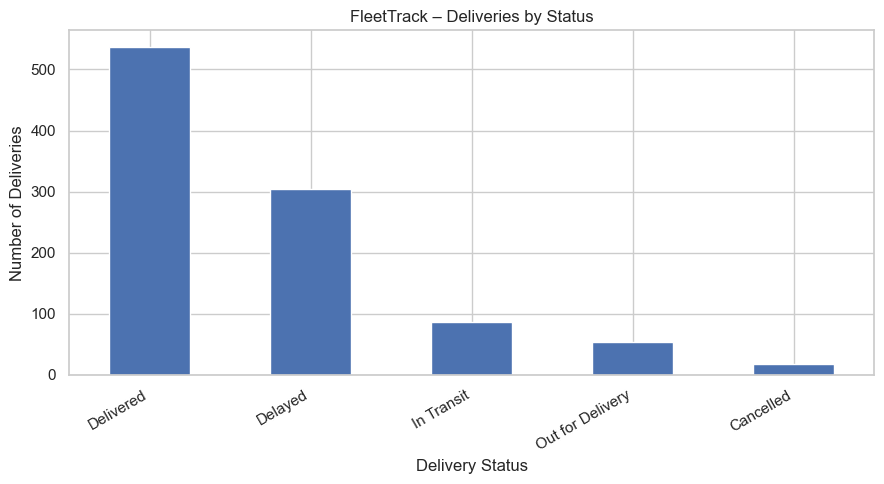

In [14]:
status_summary = (
    delivery_rows.groupby("DeliveryStatus", dropna=False)
    .agg(TotalDeliveries=("DeliveryID", "nunique"))
    .sort_values("TotalDeliveries", ascending=False)
)
display(status_summary)

plt.figure(figsize=(9, 5))
status_summary["TotalDeliveries"].plot(kind="bar")
plt.title("FleetTrack – Deliveries by Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 11. Delivery performance analysis

,TotalShipments
DeliveryPerformance,
On Time,537
Late,305
In Transit,86
Out for Delivery,54
Cancelled,18


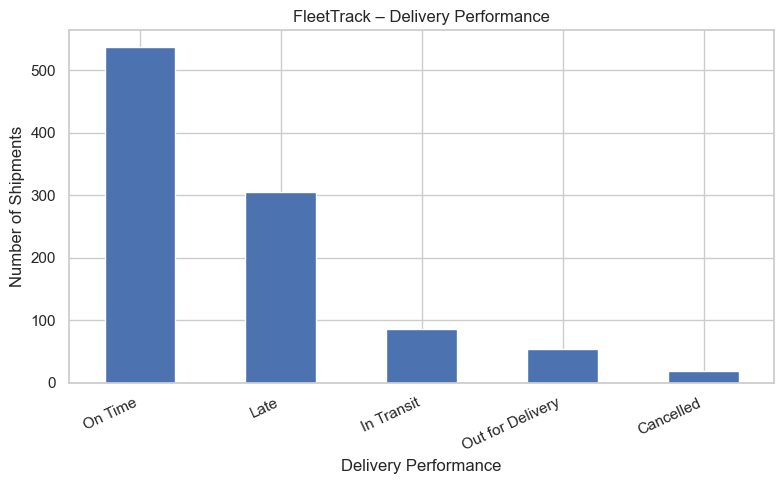

In [15]:
performance_summary = (
    delivery_rows.groupby("DeliveryPerformance", dropna=False)
    .agg(TotalShipments=("ShipmentID", "nunique"))
    .sort_values("TotalShipments", ascending=False)
)
display(performance_summary)

plt.figure(figsize=(8, 5))
performance_summary["TotalShipments"].plot(kind="bar")
plt.title("FleetTrack – Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 12. Monthly shipment trend

,BookingMonth,TotalShipments,TotalShippingCostINR,AverageShippingCostINR
0,2025-11,85,"29,427.96",346.21
1,2025-12,80,"26,376.16",329.70
2,2026-01,72,"23,627.08",328.15
3,2026-02,81,"28,451.63",351.25
4,2026-03,83,"26,578.66",320.22
5,2026-04,84,"29,052.18",345.86
6,2026-05,95,"31,194.62",328.36
7,2026-06,90,"29,624.62",329.16
8,2026-07,82,"29,451.52",359.16
9,2026-08,77,"27,059.70",351.42


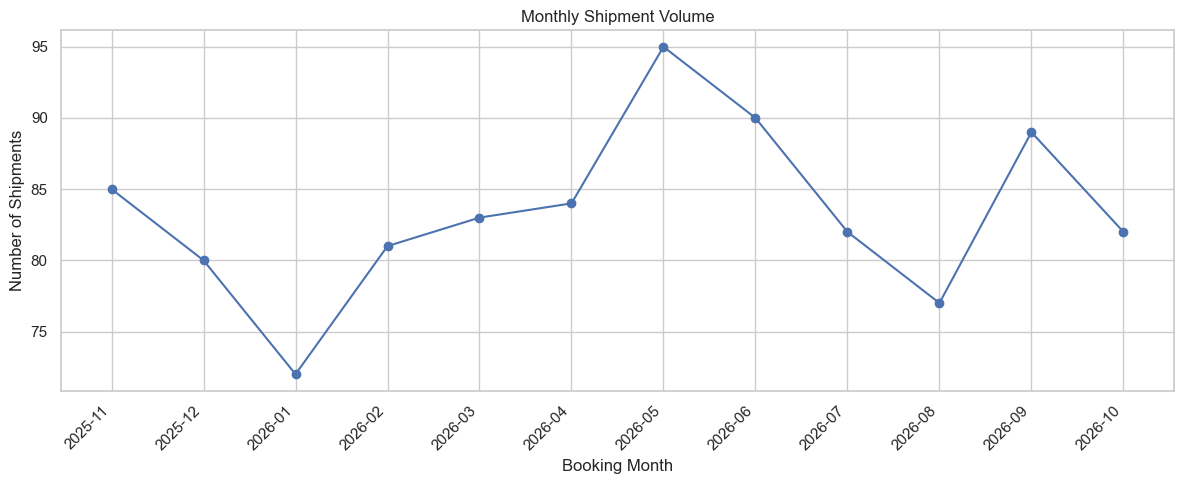

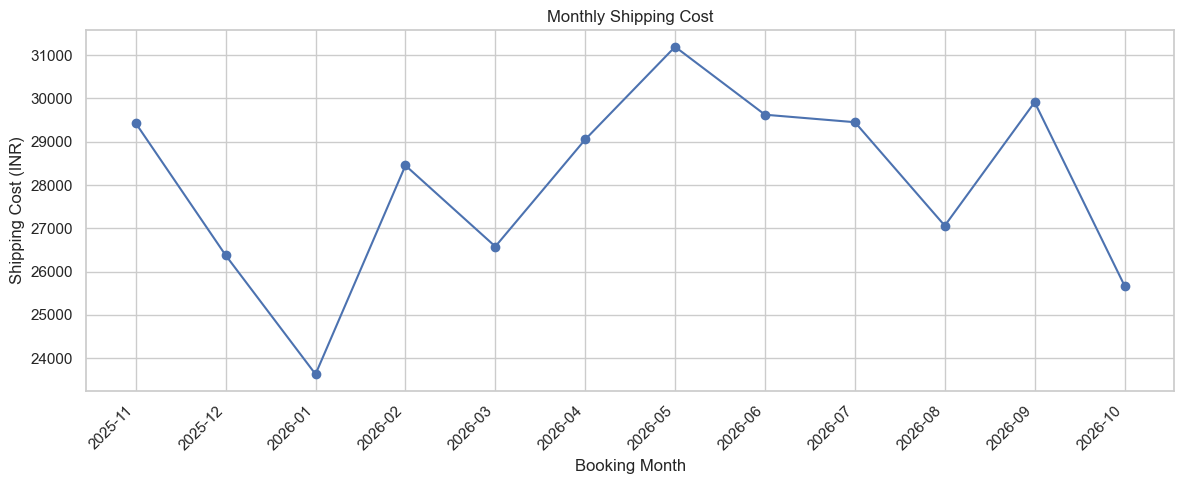

In [16]:
monthly = df.dropna(subset=["BookingDate"]).copy()
monthly["BookingMonth"] = monthly["BookingDate"].dt.to_period("M").astype(str)

monthly_summary = (
    monthly.groupby("BookingMonth")
    .agg(
        TotalShipments=("ShipmentID", "nunique"),
        TotalShippingCostINR=("ShippingCostINR", "sum"),
        AverageShippingCostINR=("ShippingCostINR", "mean")
    )
    .reset_index()
    .sort_values("BookingMonth")
)

display(monthly_summary)

plt.figure(figsize=(12, 5))
plt.plot(monthly_summary["BookingMonth"], monthly_summary["TotalShipments"], marker="o")
plt.title("Monthly Shipment Volume")
plt.xlabel("Booking Month")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(monthly_summary["BookingMonth"], monthly_summary["TotalShippingCostINR"], marker="o")
plt.title("Monthly Shipping Cost")
plt.xlabel("Booking Month")
plt.ylabel("Shipping Cost (INR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 13. Shipment priority analysis

,TotalShipments,AverageShippingCostINR,AverageWeightKg
Priority,,,
Standard,521,334.03,12.60
Same Day,248,339.36,12.74
Express,231,338.69,12.84


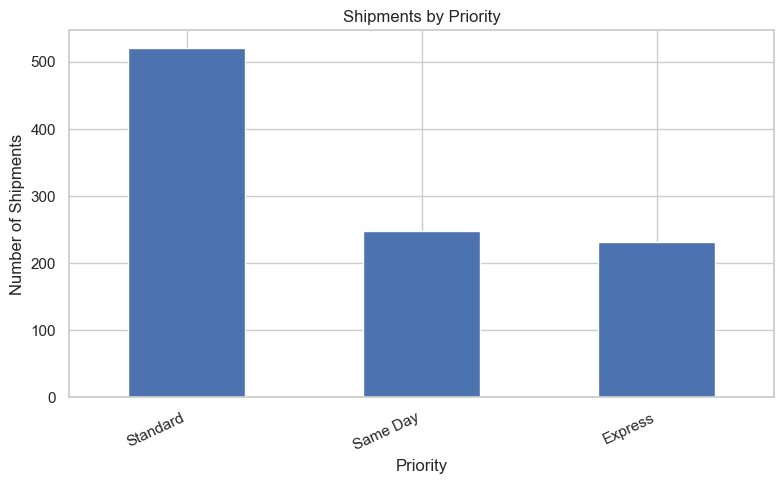

In [17]:
priority_summary = (
    df.groupby("Priority", dropna=False)
    .agg(
        TotalShipments=("ShipmentID", "nunique"),
        AverageShippingCostINR=("ShippingCostINR", "mean"),
        AverageWeightKg=("WeightKg", "mean")
    )
    .sort_values("TotalShipments", ascending=False)
)
display(priority_summary)

plt.figure(figsize=(8, 5))
priority_summary["TotalShipments"].plot(kind="bar")
plt.title("Shipments by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 14. Route performance analysis

,SourceCity,DestinationCity,TotalShipments,AverageDistanceKm,AverageShippingCostINR,AverageWeightKg
31,Kolkata,Surat,27,"1,029.00",379.39,16.00
16,Indore,Ahmedabad,25,819.00,334.48,14.41
40,Nagpur,Indore,25,231.00,232.00,11.54
48,Surat,Delhi,25,"1,050.00",352.06,13.06
15,Hyderabad,Kolkata,24,"1,437.00",386.10,12.40
35,Lucknow,Mumbai,24,363.00,258.83,12.34
20,Indore,Kochi,24,"1,417.00",417.81,14.99
0,Ahmedabad,Coimbatore,24,689.00,306.36,13.00
37,Mumbai,Nagpur,24,"1,277.00",370.46,12.49
14,Delhi,Surat,23,"1,155.00",331.71,10.98


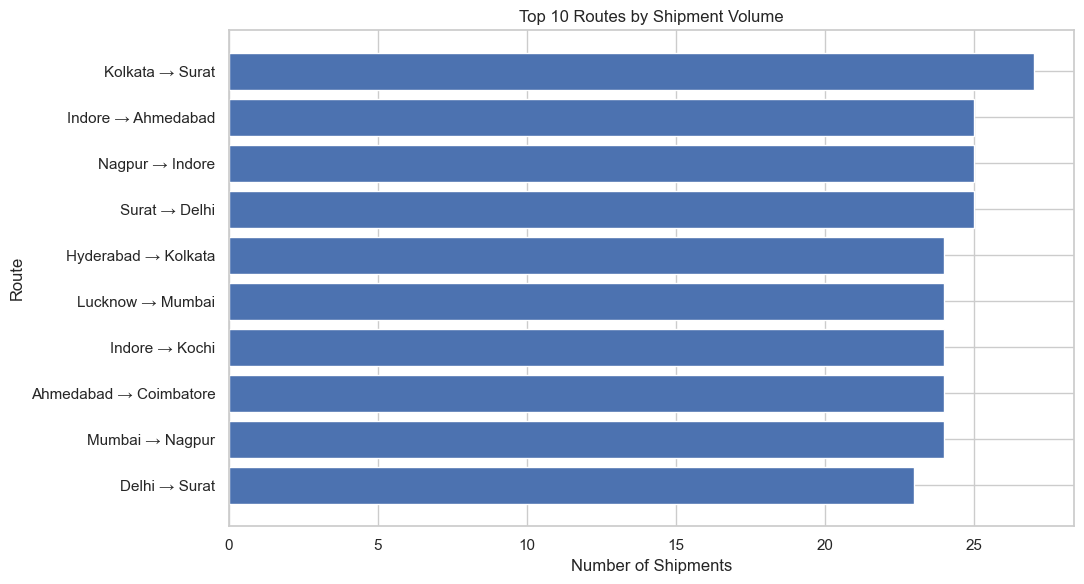

In [18]:
route_summary = (
    df.groupby(["SourceCity", "DestinationCity"], dropna=False)
    .agg(
        TotalShipments=("ShipmentID", "nunique"),
        AverageDistanceKm=("DistanceKm", "mean"),
        AverageShippingCostINR=("ShippingCostINR", "mean"),
        AverageWeightKg=("WeightKg", "mean")
    )
    .reset_index()
    .sort_values("TotalShipments", ascending=False)
)

display(route_summary.head(15))

top_routes = route_summary.head(10).copy()
top_routes["Route"] = top_routes["SourceCity"].astype(str) + " → " + top_routes["DestinationCity"].astype(str)

plt.figure(figsize=(11, 6))
plt.barh(top_routes["Route"][::-1], top_routes["TotalShipments"][::-1])
plt.title("Top 10 Routes by Shipment Volume")
plt.xlabel("Number of Shipments")
plt.ylabel("Route")
plt.tight_layout()
plt.show()


## 15. Driver performance analysis

In [19]:
driver_data = delivery_rows.dropna(subset=["DriverName"]).copy()

driver_summary = (
    driver_data.groupby("DriverName")
    .agg(
        TotalDeliveries=("DeliveryID", "nunique"),
        Delivered=("DeliveryStatus", lambda s: (s == "Delivered").sum()),
        Delayed=("DeliveryStatus", lambda s: (s == "Delayed").sum())
    )
    .reset_index()
)

driver_summary["CompletedDeliveries"] = driver_summary["Delivered"] + driver_summary["Delayed"]
driver_summary["DeliveredPercentage"] = np.where(
    driver_summary["TotalDeliveries"] > 0,
    driver_summary["Delivered"] / driver_summary["TotalDeliveries"] * 100,
    np.nan
)

driver_summary = driver_summary.sort_values(
    ["TotalDeliveries", "DeliveredPercentage"], ascending=[False, False]
)

display(driver_summary.head(15))


,DriverName,TotalDeliveries,Delivered,Delayed,CompletedDeliveries,DeliveredPercentage
96,Reyansh Sharma,18,13,3,16,72.22
67,Krishna Menon,17,8,4,12,47.06
125,Sneha Singh,17,5,7,12,29.41
9,Aarav Reddy,16,8,7,15,50.00
94,Rahul Verma,15,10,2,12,66.67
6,Aarav Das,15,5,5,10,33.33
4,Aadhya Rao,13,8,3,11,61.54
116,Sai Joshi,13,6,4,10,46.15
32,Arjun Das,12,8,2,10,66.67
53,Ishaan Reddy,12,8,2,10,66.67


## 16. Vehicle utilisation analysis

,VehicleNumber,VehicleType,TotalAssignedDeliveries
25,KA23C6422,Two-Wheeler,19
26,KA24F3316,Mini Truck,18
78,KA80G6399,LCV,18
67,KA67C7237,Two-Wheeler,18
3,KA04B6798,Mini Truck,17
43,KA41B4908,Pickup Van,16
14,KA10B7600,Heavy Truck,15
23,KA21H8479,Mini Truck,14
48,KA47B4273,Heavy Truck,14
38,KA35E5397,Pickup Van,14


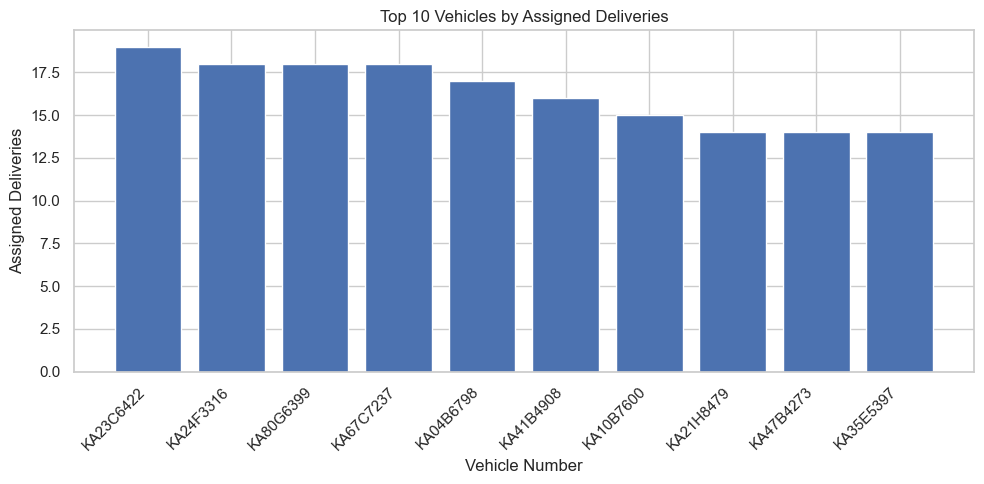

In [22]:
vehicle_data = delivery_rows.dropna(subset=["VehicleNumber"]).copy()

vehicle_summary = (
    vehicle_data.groupby(
        ["VehicleNumber", "VehicleType"],
        dropna=False
    )
    .agg(
        TotalAssignedDeliveries=("DeliveryID", "nunique")
    )
    .reset_index()
    .sort_values("TotalAssignedDeliveries", ascending=False)
)

display(vehicle_summary.head(15))

top_vehicles = vehicle_summary.head(10)
plt.figure(figsize=(10, 5))
plt.bar(top_vehicles["VehicleNumber"], top_vehicles["TotalAssignedDeliveries"])
plt.title("Top 10 Vehicles by Assigned Deliveries")
plt.xlabel("Vehicle Number")
plt.ylabel("Assigned Deliveries")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 17. Delay reason analysis

,DelayReason,TotalDelayedDeliveries
0,Operational delay,62
1,Hub congestion,61
2,Weather conditions,50
3,Vehicle breakdown,47
4,Address issue,45
5,High shipment volume,40


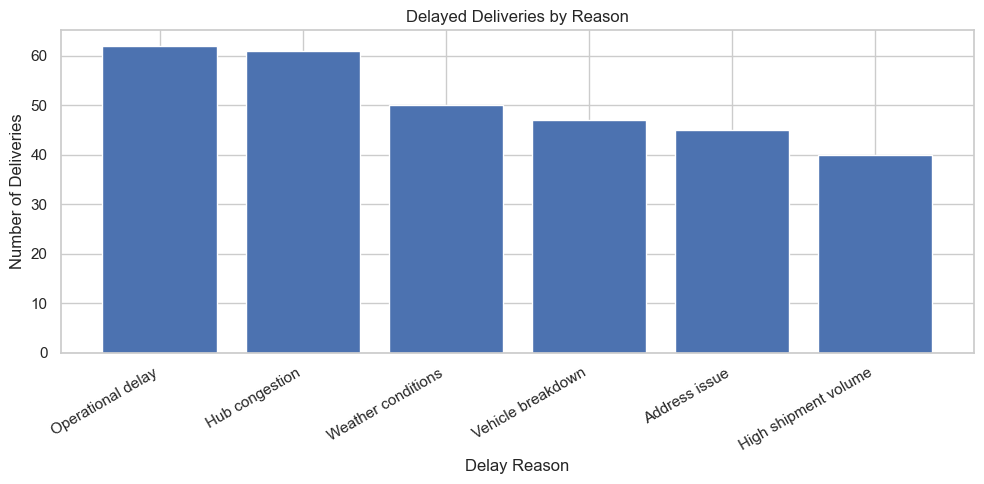

In [23]:
delayed_data = delivery_rows[delivery_rows["DeliveryStatus"] == "Delayed"].copy()

if "DelayReason" in delayed_data.columns:
    delay_reason_summary = (
        delayed_data["DelayReason"]
        .fillna("Not specified")
        .value_counts()
        .rename_axis("DelayReason")
        .reset_index(name="TotalDelayedDeliveries")
    )
    display(delay_reason_summary)

    plt.figure(figsize=(10, 5))
    plt.bar(delay_reason_summary["DelayReason"], delay_reason_summary["TotalDelayedDeliveries"])
    plt.title("Delayed Deliveries by Reason")
    plt.xlabel("Delay Reason")
    plt.ylabel("Number of Deliveries")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("DelayReason column is not available in the view.")


## 18. Customer shipment analysis

In [24]:
customer_summary = (
    df.groupby(["CustomerName", "CustomerCity"], dropna=False)
    .agg(
        TotalShipments=("ShipmentID", "nunique"),
        TotalShippingCostINR=("ShippingCostINR", "sum"),
        AverageShippingCostINR=("ShippingCostINR", "mean")
    )
    .reset_index()
    .sort_values("TotalShipments", ascending=False)
)

display(customer_summary.head(15))


,CustomerName,CustomerCity,TotalShipments,TotalShippingCostINR,AverageShippingCostINR
280,Priya Singh,Kolkata,6,"1,810.10",301.68
21,Aarav Pillai,Pune,6,"1,912.33",318.72
247,Neha Nair,Ahmedabad,6,"2,016.27",336.05
192,Kavya Desai,Bengaluru,6,"2,098.77",349.80
279,Priya Nair,Coimbatore,6,"2,325.74",387.62
246,Neha Khan,Pune,5,"1,518.86",303.77
52,Aditya Mishra,Delhi,5,"1,414.46",282.89
115,Ayaan Chopra,Delhi,5,"1,796.80",359.36
391,Vihaan Gupta,Nagpur,5,"1,898.22",379.64
170,Ishaan Sharma,Lucknow,5,"1,834.94",366.99


## 19. Correlation analysis

,DistanceKm,WeightKg,ShippingCostINR
DistanceKm,1.00,-0.01,0.51
WeightKg,-0.01,1.00,0.84
ShippingCostINR,0.51,0.84,1.00


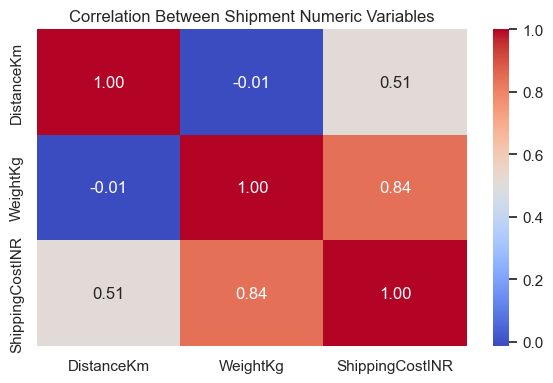

In [25]:
correlation_columns = [
    column for column in ["DistanceKm", "WeightKg", "ShippingCostINR"]
    if column in df.columns
]

if len(correlation_columns) >= 2:
    correlation_matrix = df[correlation_columns].corr(numeric_only=True)
    display(correlation_matrix)

    plt.figure(figsize=(6, 4))
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Between Shipment Numeric Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns are available for correlation analysis.")


## 20. Export analysis results

The following files are saved in the same folder as this notebook. They are analysis outputs only; the MySQL database is not modified.


In [26]:
df.to_csv("fleettrack_shipment_delivery_data.csv", index=False)
kpi_summary.to_csv("fleettrack_kpi_summary.csv", index=False)
monthly_summary.to_csv("fleettrack_monthly_summary.csv", index=False)
status_summary.to_csv("fleettrack_delivery_status_summary.csv")
performance_summary.to_csv("fleettrack_delivery_performance_summary.csv")
route_summary.to_csv("fleettrack_route_summary.csv", index=False)
driver_summary.to_csv("fleettrack_driver_summary.csv", index=False)
vehicle_summary.to_csv("fleettrack_vehicle_summary.csv", index=False)
customer_summary.to_csv("fleettrack_customer_summary.csv", index=False)

print("Analysis outputs exported successfully.")


Analysis outputs exported successfully.


## 21. Close the MySQL connection

In [27]:
if "conn" in globals() and conn.is_connected():
    conn.close()
    print("MySQL connection closed.")
else:
    print("No active MySQL connection to close.")


MySQL connection closed.
